# Prepare three supervised horizon datasets

Reads `nj_daily_features.csv.gz` and writes three chronologically ordered copies for modeling.

| File | Target |
|---|---|
| `supervised_horizon_1_next_day.csv.gz` | cases on day t+1 |
| `supervised_horizon_2.csv.gz` | cases on day t+2 |
| `supervised_horizon_3.csv.gz` | cases on day t+3 |

Same predictors in every file. Last column is always `target_cases`. No train/test split is applied here.

Candidate predictors are kept so a later model can rank them. Flags and metadata are excluded. Rows with any blank predictor or blank target are dropped so these files are ready to load.

In [1]:
from pathlib import Path

import pandas as pd

PROJECT = Path.cwd()
if not (PROJECT / "nj_daily_features.csv.gz").is_file():
    PROJECT = PROJECT / "Weikun"
assert (PROJECT / "nj_daily_features.csv.gz").is_file(), "Open this notebook from Weikun or the repo root."

INPUT = PROJECT / "nj_daily_features.csv.gz"
OUTPUT = PROJECT / "supervised_horizon_outputs"
OUTPUT.mkdir(parents=True, exist_ok=True)

HORIZONS = {
    1: "supervised_horizon_1_next_day.csv.gz",
    2: "supervised_horizon_2.csv.gz",
    3: "supervised_horizon_3.csv.gz",
}

# Candidate predictors. The model can rank these later.
FEATURE_COLUMNS = [
    "day_of_week",
    "month",
    "cases_today",
    "cases_lag_1",
    "cases_lag_7",
    "cases_lag_14",
    "cases_sum_7d",
    "cases_mean_7d",
    "case_std_7d",
    "cases_sum_14d",
    "cases_mean_14d",
    "case_std_14d",
    "week_over_week_change",
    "case_velocity",
    "case_acceleration",
    "case_jerk",
    "days_since_last_observed_case",
    "population",
    "land_area_sq_km",
    "population_density_per_sq_km",
    "resident_jobs_nj_network",
    "workplace_jobs_nj_network",
    "inbound_jobs_external_nj",
    "outbound_jobs_external_nj",
    "internal_jobs",
    "external_inbound_share_nj_network",
    "external_outbound_share_nj_network",
    "case_rate_today_per_100k",
    "case_rate_7d_per_100k",
    "case_rate_14d_per_100k",
    "nj_covid_pressure_7d",
    "nj_covid_pressure_14d",
]

ID_COLUMNS = ["zip", "date"]

In [2]:
def build_horizon(panel: pd.DataFrame, horizon: int) -> pd.DataFrame:
    frame = panel.loc[:, ["zip", "date"] + FEATURE_COLUMNS].copy()
    frame["target_cases"] = frame.groupby("zip", sort=False)["cases_today"].shift(-horizon)

    # Complete predictor + label rows only.
    frame = frame.dropna(subset=FEATURE_COLUMNS + ["target_cases"]).copy()
    frame["target_cases"] = frame["target_cases"].astype("int64")
    frame = frame.sort_values(["date", "zip"]).reset_index(drop=True)
    return frame[ID_COLUMNS + FEATURE_COLUMNS + ["target_cases"]]


panel = pd.read_csv(
    INPUT,
    dtype={"zip": "string", "state": "string"},
    parse_dates=["date"],
)
missing = [c for c in FEATURE_COLUMNS if c not in panel.columns]
assert not missing, f"Missing columns: {missing}"
assert not panel.duplicated(["zip", "date"]).any()

print("Input rows:", f"{len(panel):,}")
print("Date range:", panel.date.min().date(), "to", panel.date.max().date())
print("Candidate features:", len(FEATURE_COLUMNS))

summaries = []
frames = {}

for horizon, filename in HORIZONS.items():
    frame = build_horizon(panel, horizon)
    path = OUTPUT / filename
    frame.to_csv(path, index=False, compression="gzip")
    frames[horizon] = frame
    null_total = int(frame.isna().sum().sum())
    summaries.append({
        "horizon_days": horizon,
        "file": filename,
        "rows": len(frame),
        "zips": frame.zip.nunique(),
        "features": len(FEATURE_COLUMNS),
        "date_min": frame.date.min().date(),
        "date_max": frame.date.max().date(),
        "null_cells": null_total,
        "last_column": frame.columns[-1],
        "path": str(path.resolve()),
    })
    print(f"horizon {horizon}: {len(frame):,} rows -> {path.name} | null cells: {null_total}")

summary = pd.DataFrame(summaries)
summary.to_csv(OUTPUT / "preparation_summary.csv", index=False)
summary

Input rows: 873,678
Date range: 2020-01-01 to 2023-12-31
Candidate features: 32
horizon 1: 629,527 rows -> supervised_horizon_1_next_day.csv.gz | null cells: 0
horizon 2: 629,071 rows -> supervised_horizon_2.csv.gz | null cells: 0
horizon 3: 628,615 rows -> supervised_horizon_3.csv.gz | null cells: 0


,horizon_days,file,rows,zips,features,date_min,date_max,null_cells,last_column,path
0,1,supervised_horizon_1_next_day.csv.gz,629527,456,32,2020-02-15,2023-12-30,0,target_cases,/Users/dhruvesh/Desktop/Fall 2026/Analytics/Ju...
1,2,supervised_horizon_2.csv.gz,629071,456,32,2020-02-15,2023-12-29,0,target_cases,/Users/dhruvesh/Desktop/Fall 2026/Analytics/Ju...
2,3,supervised_horizon_3.csv.gz,628615,456,32,2020-02-15,2023-12-28,0,target_cases,/Users/dhruvesh/Desktop/Fall 2026/Analytics/Ju...


## Null check on the saved files

These tables were built with `dropna` on every predictor and on `target_cases`, so saved files should have zero nulls. The cell below counts nulls by column anyway.

In [3]:
null_reports = []
for horizon, filename in HORIZONS.items():
    frame = frames[horizon]
    null_count = frame.isna().sum()
    null_count = null_count.loc[null_count.gt(0)]
    print(f"\nHorizon {horizon} ({filename})")
    print("Total null cells:", int(frame.isna().sum().sum()))
    if null_count.empty:
        print("No null values in any column.")
    else:
        display(null_count.to_frame("null_count"))
    null_reports.append({
        "horizon_days": horizon,
        "null_cells": int(frame.isna().sum().sum()),
        "columns_with_nulls": int((frame.isna().sum() > 0).sum()),
    })

pd.DataFrame(null_reports)


Horizon 1 (supervised_horizon_1_next_day.csv.gz)
Total null cells: 0
No null values in any column.

Horizon 2 (supervised_horizon_2.csv.gz)


Total null cells: 0
No null values in any column.



Horizon 3 (supervised_horizon_3.csv.gz)
Total null cells: 0
No null values in any column.


,horizon_days,null_cells,columns_with_nulls
0,1,0,0
1,2,0,0
2,3,0,0


## Preview: horizon 1 (next day)

In [4]:
horizon_1 = frames[1]
print(horizon_1.shape)
print("Last column:", horizon_1.columns[-1])
horizon_1.head()

(629527, 35)
Last column: target_cases


,zip,date,day_of_week,month,cases_today,cases_lag_1,cases_lag_7,cases_lag_14,cases_sum_7d,cases_mean_7d,...,outbound_jobs_external_nj,internal_jobs,external_inbound_share_nj_network,external_outbound_share_nj_network,case_rate_today_per_100k,case_rate_7d_per_100k,case_rate_14d_per_100k,nj_covid_pressure_7d,nj_covid_pressure_14d,target_cases
0,07023,2020-02-15,6,2,1,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,12.941633,12.941633,12.941633,0.006764,0.006764,0
1,07108,2020-02-15,6,2,1,0.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,3.537694,3.537694,3.537694,0.003348,0.003348,0
2,07023,2020-02-16,7,2,0,1.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0
3,07108,2020-02-16,7,2,0,1.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,0.000000,3.537694,3.537694,0.003348,0.003348,0
4,07023,2020-02-17,1,2,0,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0


## Preview: horizon 2

In [5]:
horizon_2 = frames[2]
print(horizon_2.shape)
print("Last column:", horizon_2.columns[-1])
horizon_2.head()

(629071, 35)
Last column: target_cases


,zip,date,day_of_week,month,cases_today,cases_lag_1,cases_lag_7,cases_lag_14,cases_sum_7d,cases_mean_7d,...,outbound_jobs_external_nj,internal_jobs,external_inbound_share_nj_network,external_outbound_share_nj_network,case_rate_today_per_100k,case_rate_7d_per_100k,case_rate_14d_per_100k,nj_covid_pressure_7d,nj_covid_pressure_14d,target_cases
0,07023,2020-02-15,6,2,1,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,12.941633,12.941633,12.941633,0.006764,0.006764,0
1,07108,2020-02-15,6,2,1,0.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,3.537694,3.537694,3.537694,0.003348,0.003348,0
2,07023,2020-02-16,7,2,0,1.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0
3,07108,2020-02-16,7,2,0,1.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,0.000000,3.537694,3.537694,0.003348,0.003348,0
4,07023,2020-02-17,1,2,0,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0


## Preview: horizon 3

In [3]:
horizon_3 = frames[3]
print(horizon_3.shape)
print("Last column:", horizon_3.columns[-1])
horizon_3.head(15)

(628615, 35)
Last column: target_cases


,zip,date,day_of_week,month,cases_today,cases_lag_1,cases_lag_7,cases_lag_14,cases_sum_7d,cases_mean_7d,...,outbound_jobs_external_nj,internal_jobs,external_inbound_share_nj_network,external_outbound_share_nj_network,case_rate_today_per_100k,case_rate_7d_per_100k,case_rate_14d_per_100k,nj_covid_pressure_7d,nj_covid_pressure_14d,target_cases
0,07023,2020-02-15,6,2,1,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,12.941633,12.941633,12.941633,0.006764,0.006764,0
1,07108,2020-02-15,6,2,1,0.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,3.537694,3.537694,3.537694,0.003348,0.003348,0
2,07023,2020-02-16,7,2,0,1.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0
3,07108,2020-02-16,7,2,0,1.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,0.000000,3.537694,3.537694,0.003348,0.003348,0
4,07023,2020-02-17,1,2,0,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0
5,07108,2020-02-17,1,2,0,0.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,0.000000,3.537694,3.537694,0.003348,0.003348,0
6,07023,2020-02-18,2,2,0,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0
7,07108,2020-02-18,2,2,0,0.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,0.000000,3.537694,3.537694,0.003348,0.003348,0
8,07023,2020-02-19,3,2,0,0.0,0.0,0.0,1.0,0.142857,...,3047,96,0.942342,0.969456,0.000000,12.941633,12.941633,0.006764,0.006764,0
9,07108,2020-02-19,3,2,0,0.0,0.0,0.0,1.0,0.142857,...,8487,148,0.921402,0.982860,0.000000,3.537694,3.537694,0.003348,0.003348,0


## Cases today: New Brunswick, Princeton, Jersey City

Plotted from the full `nj_daily_features.csv.gz` panel (not the dropped-null training copies), so places like New Brunswick still appear even if pressure was blank on some days.

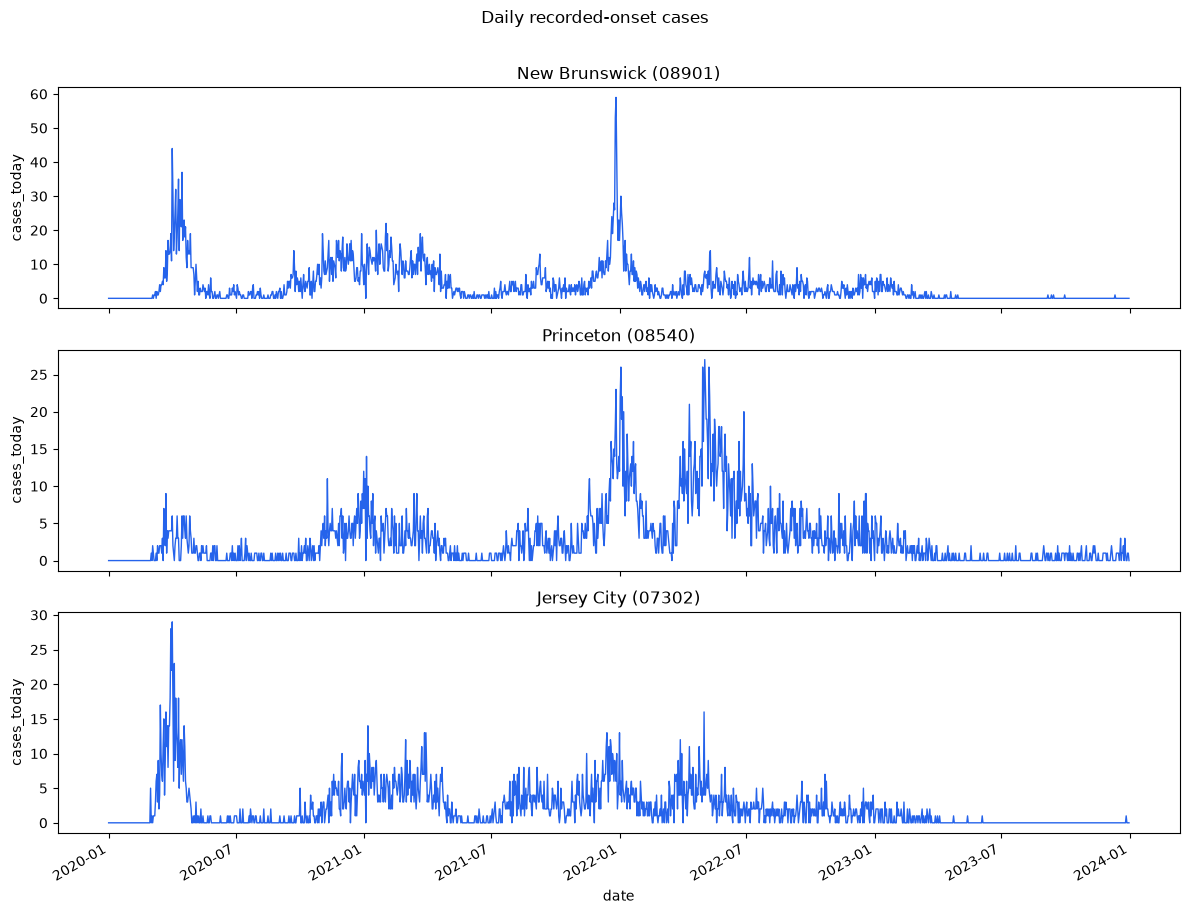

In [4]:
import matplotlib.pyplot as plt

# Popular NJ ZIPs: New Brunswick, Princeton, and Jersey City (downtown).
places = {
    "08901": "New Brunswick",
    "08540": "Princeton",
    "07302": "Jersey City",
}

chart = panel.loc[panel.zip.isin(places)].copy()
chart["place"] = chart.zip.map(places)
chart = chart.sort_values(["place", "date"])

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (zipcode, name) in zip(axes, places.items()):
    one = chart.loc[chart.zip.eq(zipcode)]
    ax.plot(one.date, one.cases_today, color="#2563EB", linewidth=1)
    ax.set_ylabel("cases_today")
    ax.set_title(f"{name} ({zipcode})")

axes[-1].set_xlabel("date")
fig.suptitle("Daily recorded-onset cases", y=1.01)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()